In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder, StandardScaler

In [2]:
# Load only the train file (has Loan_Status)
df = pd.read_csv('../data/train_u6lujuX_CVtuZ9i.csv')

# Drop Loan_ID — it's just an identifier, not a feature
df = df.drop(columns=['Loan_ID'])

print("Shape after dropping Loan_ID:", df.shape)
df.head()

Shape after dropping Loan_ID: (614, 12)


,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y


In [3]:
# Mode fill for categorical columns
categorical_cols = ['Gender', 'Married', 'Dependents', 'Self_Employed']

for col in categorical_cols:
    mode_value = df[col].mode()[0]
    df[col] = df[col].fillna(mode_value)
    print(f"{col} → filled with mode: '{mode_value}'")

Gender → filled with mode: 'Male'
Married → filled with mode: 'Yes'
Dependents → filled with mode: '0'
Self_Employed → filled with mode: 'No'


In [4]:
# Median fill for LoanAmount (safer than mean for money values)
df['LoanAmount'] = df['LoanAmount'].fillna(df['LoanAmount'].median())

# Mode fill for Loan_Amount_Term (360 months dominates)
df['Loan_Amount_Term'] = df['Loan_Amount_Term'].fillna(df['Loan_Amount_Term'].mode()[0])

# Mode fill for Credit_History (binary 0/1 column)
df['Credit_History'] = df['Credit_History'].fillna(df['Credit_History'].mode()[0])

print("Missing values remaining:")
print(df.isnull().sum())

Missing values remaining:
Gender               0
Married              0
Dependents           0
Education            0
Self_Employed        0
ApplicantIncome      0
CoapplicantIncome    0
LoanAmount           0
Loan_Amount_Term     0
Credit_History       0
Property_Area        0
Loan_Status          0
dtype: int64


In [5]:
# Combine applicant and co-applicant income into one feature
df['Total_Income'] = df['ApplicantIncome'] + df['CoapplicantIncome']

# Drop the originals — Total_Income captures them both
df = df.drop(columns=['ApplicantIncome', 'CoapplicantIncome'])

print("New shape:", df.shape)

New shape: (614, 11)


In [6]:
# How much loan are they requesting relative to their income?
# High ratio = higher risk
df['Income_to_Loan_Ratio'] = df['Total_Income'] / df['LoanAmount']

print(df['Income_to_Loan_Ratio'].describe())

count    614.000000
mean      51.189296
std       37.709429
min       12.090196
25%       35.513864
50%       41.443547
75%       52.027847
max      396.366667
Name: Income_to_Loan_Ratio, dtype: float64


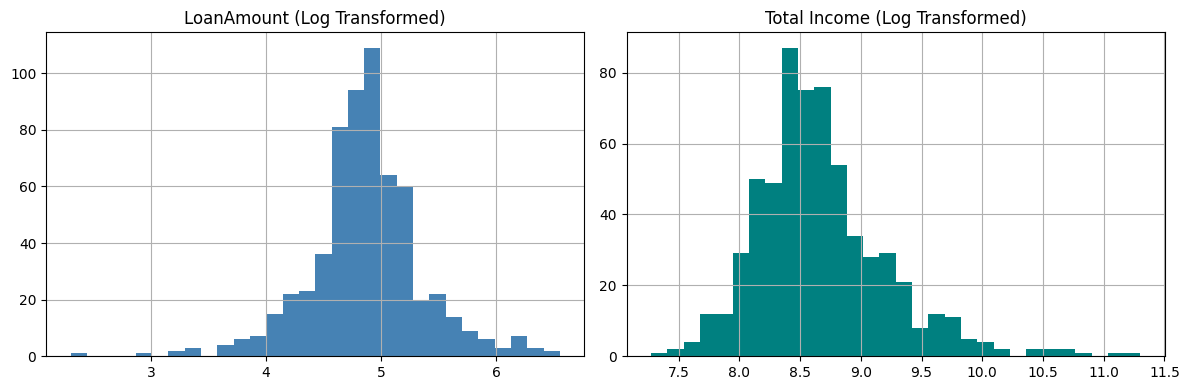

In [7]:
# Income and loan amount are heavily skewed (a few very rich people)
# Log transform brings them closer to a normal distribution
# which helps gradient boosting models learn better

df['Total_Income_Log'] = np.log1p(df['Total_Income'])
df['LoanAmount_Log'] = np.log1p(df['LoanAmount'])

# Drop the originals now that we have log versions
df = df.drop(columns=['Total_Income', 'LoanAmount'])

# Visualize before vs after for LoanAmount
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
df['LoanAmount_Log'].hist(ax=axes[0], bins=30, color='steelblue')
axes[0].set_title('LoanAmount (Log Transformed)')
df['Total_Income_Log'].hist(ax=axes[1], bins=30, color='teal')
axes[1].set_title('Total Income (Log Transformed)')
plt.tight_layout()
plt.show()

In [8]:
# These columns only have 2 options — simple 0/1 replacement
binary_cols = {
    'Gender':       {'Male': 1, 'Female': 0},
    'Married':      {'Yes': 1, 'No': 0},
    'Education':    {'Graduate': 1, 'Not Graduate': 0},
    'Self_Employed':{'Yes': 1, 'No': 0},
    'Loan_Status':  {'Y': 1, 'N': 0}   # target column
}

for col, mapping in binary_cols.items():
    df[col] = df[col].map(mapping)
    print(f"{col} → encoded")

Gender → encoded
Married → encoded
Education → encoded
Self_Employed → encoded
Loan_Status → encoded


In [9]:
# Dependents has a '3+' value so we handle it separately
df['Dependents'] = df['Dependents'].replace('3+', 3).astype(int)
print(df['Dependents'].value_counts())

Dependents
0    360
1    102
2    101
3     51
Name: count, dtype: int64


In [10]:
# 3 categories: Urban, Semiurban, Rural
# Use Label Encoding (0, 1, 2)
le = LabelEncoder()
df['Property_Area'] = le.fit_transform(df['Property_Area'])
print(df['Property_Area'].value_counts())

Property_Area
1    233
2    202
0    179
Name: count, dtype: int64


In [11]:
print("Final shape:", df.shape)
print("\nData types:\n", df.dtypes)
print("\nMissing values:\n", df.isnull().sum())
print("\nFirst 5 rows:")
df.head()

Final shape: (614, 12)

Data types:
 Gender                    int64
Married                   int64
Dependents                int64
Education                 int64
Self_Employed             int64
Loan_Amount_Term        float64
Credit_History          float64
Property_Area             int64
Loan_Status               int64
Income_to_Loan_Ratio    float64
Total_Income_Log        float64
LoanAmount_Log          float64
dtype: object

Missing values:
 Gender                  0
Married                 0
Dependents              0
Education               0
Self_Employed           0
Loan_Amount_Term        0
Credit_History          0
Property_Area           0
Loan_Status             0
Income_to_Loan_Ratio    0
Total_Income_Log        0
LoanAmount_Log          0
dtype: int64

First 5 rows:


,Gender,Married,Dependents,Education,Self_Employed,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status,Income_to_Loan_Ratio,Total_Income_Log,LoanAmount_Log
0,1,0,0,1,0,360.0,1.0,2,1,45.695312,8.674197,4.859812
1,1,1,1,1,0,360.0,1.0,0,0,47.585938,8.714732,4.859812
2,1,1,0,1,1,360.0,1.0,2,1,45.454545,8.006701,4.204693
3,1,1,0,0,0,360.0,1.0,2,1,41.175000,8.505525,4.795791
4,1,0,0,1,0,360.0,1.0,2,1,42.553191,8.699681,4.955827


In [12]:
df.to_csv('../data/processed_loan_data.csv', index=False)
print("✅ Saved to data/processed_loan_data.csv")

✅ Saved to data/processed_loan_data.csv


# Phase 2 — Preprocessing & Feature Engineering

## Steps Performed

### Missing Value Treatment
- Categorical columns → filled with mode
- LoanAmount → filled with median (robust to outliers)
- Credit_History → filled with mode (binary column)

### Feature Engineering
- Created `Total_Income` = ApplicantIncome + CoapplicantIncome
- Created `Income_to_Loan_Ratio` = Total_Income / LoanAmount
- Log transformed `Total_Income` and `LoanAmount` to reduce skew

### Encoding
- Binary columns mapped to 0/1
- Dependents: '3+' replaced with 3
- Property_Area: Label Encoded (0/1/2)

### Output
- Saved clean dataset to: data/processed_loan_data.csv
- Final shape: 614 rows, 11 columns (ready for modeling)

In [13]:
# Verify the saved file loads correctly
test = pd.read_csv('../data/processed_loan_data.csv')
print("Shape:", test.shape)
print("Columns:", test.columns.tolist())
print("Missing values:", test.isnull().sum().sum())
test.head()

Shape: (614, 12)
Columns: ['Gender', 'Married', 'Dependents', 'Education', 'Self_Employed', 'Loan_Amount_Term', 'Credit_History', 'Property_Area', 'Loan_Status', 'Income_to_Loan_Ratio', 'Total_Income_Log', 'LoanAmount_Log']
Missing values: 0


,Gender,Married,Dependents,Education,Self_Employed,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status,Income_to_Loan_Ratio,Total_Income_Log,LoanAmount_Log
0,1,0,0,1,0,360.0,1.0,2,1,45.695312,8.674197,4.859812
1,1,1,1,1,0,360.0,1.0,0,0,47.585938,8.714732,4.859812
2,1,1,0,1,1,360.0,1.0,2,1,45.454545,8.006701,4.204693
3,1,1,0,0,0,360.0,1.0,2,1,41.175000,8.505525,4.795791
4,1,0,0,1,0,360.0,1.0,2,1,42.553191,8.699681,4.955827
